

# Item based filtering
This approach is mostly preferred since the movie don't change much. We can rerun this model once a week unlike User based where we have to frequently run the model.

In this kernel, We look at the implementation of Item based filtering

In [1]:
import pandas as pd
import numpy as np

from scipy.sparse import csr_matrix
from sklearn.neighbors import NearestNeighbors

import matplotlib.pyplot as plt
import seaborn as sns



In [2]:
#read the dataset
movies = pd.read_csv('data/movies.csv') #read csv file in data/movies.csv
ratings = pd.read_csv('data/ratings.csv') #read csv file in data/ratings.csv

In [3]:
#print the head of the ratings to see some of its features
ratings.head()

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


Ratings dataset has 
* userId - unique for each user
* movieId - using this feature ,we take the title of the movie from movies dataset
* rating - Ratings given by each user to all the movies using this we are going to predict the top 10 similar movies

In [4]:
#print the head of the movies to see some of its features\
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


Movie dataset has 
* movieId - once the recommendation is done, we get list of all similar movieId and get the title for each movie from this dataset. 
* genres -  which is not required for this filtering approach

In [5]:
#display the ratings from users per movies
#in other words, change the form of the table from what you saw in ratings.head()
#to something you could see as movie ratings per users
#so, transform the dataset of ratings to have the index as movieid.
final_dataset = ratings.pivot(index='movieId', columns='userId', values='rating')
final_dataset.head()

userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
movieId,,,,,,,,,,,,,,,,,,,,,
1,4.0,NaN,NaN,NaN,4.0,NaN,4.5,NaN,NaN,NaN,...,4.0,NaN,4.0,3.0,4.0,2.5,4.0,2.5,3.0,5.0
2,NaN,NaN,NaN,NaN,NaN,4.0,NaN,4.0,NaN,NaN,...,NaN,4.0,NaN,5.0,3.5,NaN,NaN,2.0,NaN,NaN
3,4.0,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
# How should you handle missing values here?
#for now, just fill the NaN  as 0
final_dataset.fillna(0, inplace=True)
final_dataset.head()

userId,1,2,3,4,5,6,7,8,9,10,...,601,602,603,604,605,606,607,608,609,610
movieId,,,,,,,,,,,,,,,,,,,,,
1,4.0,0.0,0.0,0.0,4.0,0.0,4.5,0.0,0.0,0.0,...,4.0,0.0,4.0,3.0,4.0,2.5,4.0,2.5,3.0,5.0
2,0.0,0.0,0.0,0.0,0.0,4.0,0.0,4.0,0.0,0.0,...,0.0,4.0,0.0,5.0,3.5,0.0,0.0,2.0,0.0,0.0
3,4.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0


In a real world, ratings are very sparse and data points are mostly collected from very popular movies and highly engaged users. So we will reduce the noise by adding some filters and qualify the movies for the final dataset.
* To qualify a movie, minimum 10 users should have voted a movie.
* To qualify a user, minimum 50 movies should have voted by the user.


In [7]:
# Count the Number of Users Who Voted for Each Movie:
# Group the DataFrame by movieId and count the number of ratings for each movie.

no_user_voted = ratings.groupby('movieId')['rating'].agg('count')


In [8]:
no_user_voted

movieId
1         215
2         110
3          52
4           7
5          49
         ... 
193581      1
193583      1
193585      1
193587      1
193609      1
Name: rating, Length: 9724, dtype: int64

In [9]:
#Count the Number of Movies Each User Has Voted For:
#Group the DataFrame by userId and count the number of ratings each user has made.
no_movies_voted = ratings.groupby('userId')['rating'].agg('count')
no_movies_voted

userId
1       232
2        29
3        39
4       216
5        44
       ... 
606    1115
607     187
608     831
609      37
610    1302
Name: rating, Length: 610, dtype: int64

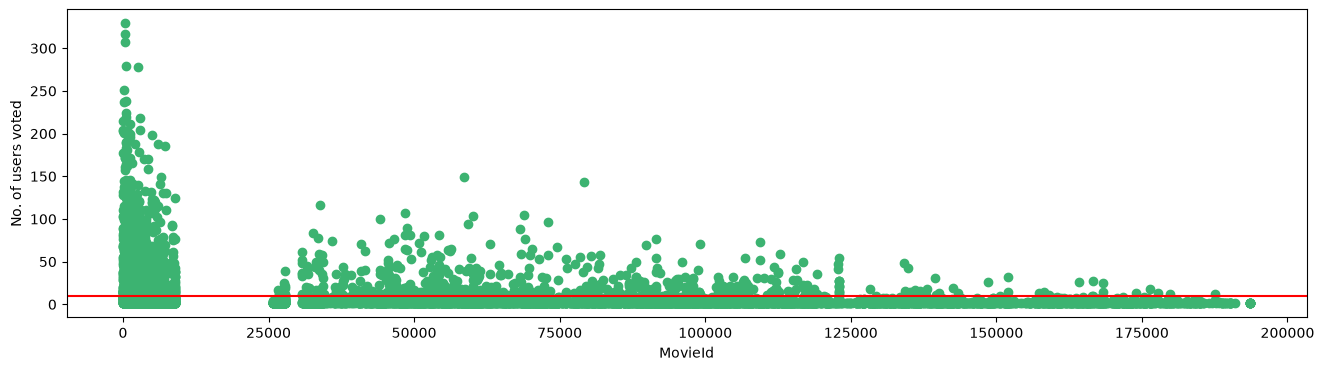

In [10]:


f,ax = plt.subplots(1,1,figsize=(16,4))
plt.scatter(no_user_voted.index, no_user_voted.values, color='mediumseagreen') #scatter plot the number of users voted
plt.axhline(y=10,color='r') #add this line as a threshold
plt.xlabel('MovieId')
plt.ylabel('No. of users voted')
plt.show()

In [11]:
#now keep the movies that where voted by more than 10 users.
final_dataset = final_dataset.loc[no_user_voted[no_user_voted > 10].index, :]

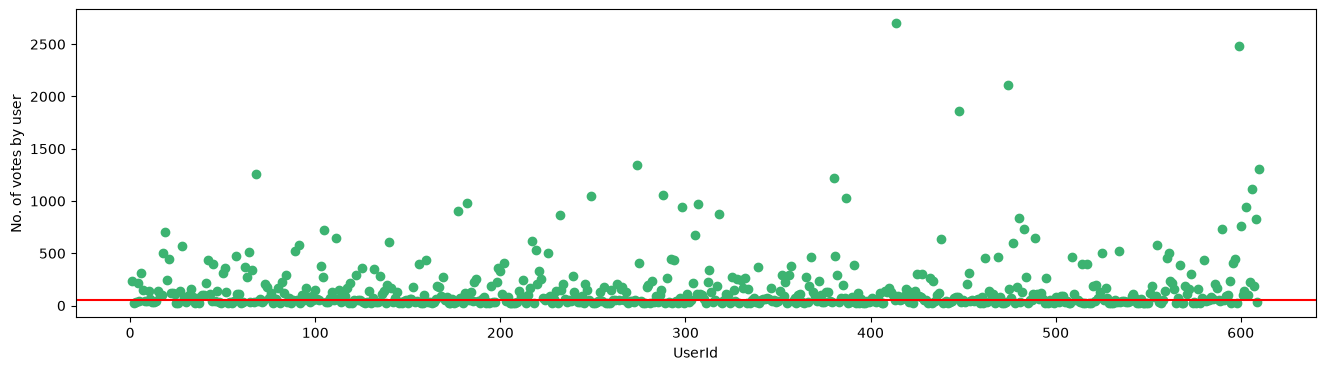

In [12]:
f,ax = plt.subplots(1,1,figsize=(16,4))
plt.scatter(no_movies_voted.index, no_movies_voted.values, color='mediumseagreen') #scatter plot the number of movies 
plt.axhline(y=50,color='r') #this is the threshold of movies voted from users that voted more than 50 movies
plt.xlabel('UserId')
plt.ylabel('No. of votes by user')
plt.show()

In [13]:
#now keep only the movies that has users voting for minimum of 50 movies
final_dataset=final_dataset.loc[:,no_movies_voted[no_movies_voted > 50].index]
final_dataset 

userId,1,4,6,7,10,11,15,16,17,18,...,600,601,602,603,604,605,606,607,608,610
movieId,,,,,,,,,,,,,,,,,,,,,
1,4.0,0.0,0.0,4.5,0.0,0.0,2.5,0.0,4.5,3.5,...,2.5,4.0,0.0,4.0,3.0,4.0,2.5,4.0,2.5,5.0
2,0.0,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,3.0,...,4.0,0.0,4.0,0.0,5.0,3.5,0.0,0.0,2.0,0.0
3,4.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0
5,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,2.5,0.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0
6,4.0,0.0,4.0,0.0,0.0,5.0,0.0,0.0,0.0,4.0,...,0.0,0.0,3.0,4.0,3.0,0.0,0.0,0.0,0.0,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
174055,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
176371,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
177765,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,4.5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Our final_dataset has dimensions of **2121 * 378** where most of the values are sparse. I took only small dataset but for
original large dataset of movie lens which has more than **100000** features, this will sure hang our system when this has 
feed to model. To reduce the sparsity we use csr_matric scipy lib. I'll give an example how it works

In [14]:
sample = np.array([[0,0,3,0,0],[4,0,0,0,2],[0,0,0,0,1]])
sparsity = 1.0 - ( np.count_nonzero(sample) / float(sample.size) )
print(sparsity)

0.7333333333333334


In [15]:
csr_sample = csr_matrix(sample)
print(csr_sample)

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 4 stored elements and shape (3, 5)>
  Coords	Values
  (0, 2)	3
  (1, 0)	4
  (1, 4)	2
  (2, 4)	1


* As you can see there is no sparse value in the csr_sample and values are assigned as rows and column index. for the 0th row and 2nd column , value is 3 . Look at the original dataset where the values at the right place. This is how it works using todense method you can take it back to original dataset.
* Most of the sklearn works with sparse matrix. surely this will improve our performance

In [16]:
csr_data = csr_matrix(final_dataset.values)
final_dataset.reset_index(inplace=True)

C:\Users\engze\AppData\Local\Temp\ipykernel_22608\2791641364.py:2: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  final_dataset.reset_index(inplace=True)


In [28]:
from sklearn.cluster import KMeans

inertias = []
K = range(1,10)
for k in K:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(csr_data)
    inertias.append(model.inertia_)

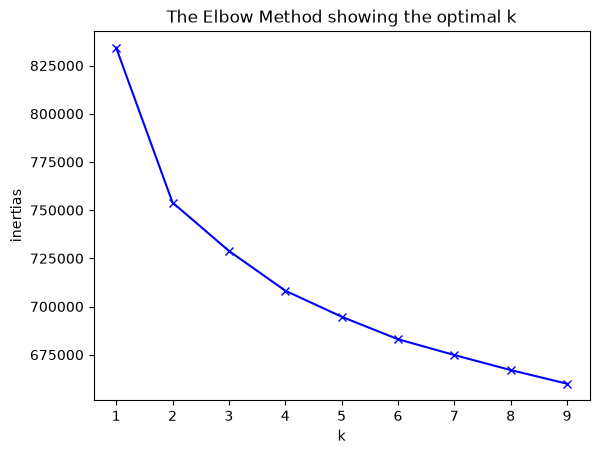

In [26]:
plt.plot(K, inertias, 'bx-')
plt.xlabel('k')
plt.ylabel('inertias')
plt.title('The Elbow Method showing the optimal k')
plt.show()

In [32]:
from sklearn.metrics import silhouette_score

sil_avg = []
range_n_clusters = [2, 3, 4, 5, 6, 7, 8]

for k in range_n_clusters:
 kmeans = KMeans(n_clusters = k).fit(csr_data)
 labels = kmeans.labels_
 sil_avg.append(silhouette_score(csr_data, labels, metric = 'euclidean')) #todo: add other values for metric we can test

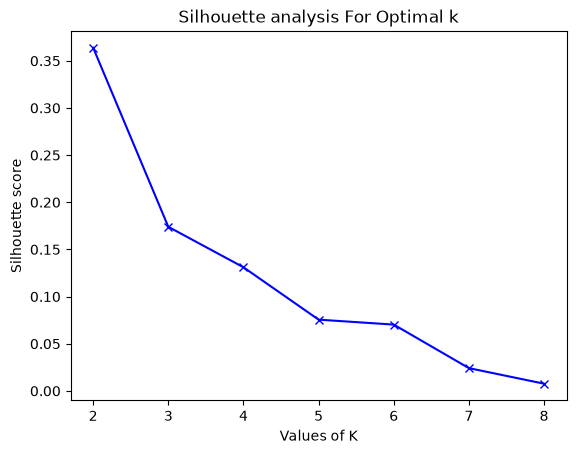

In [30]:
plt.plot(range_n_clusters,sil_avg,'bx-')
plt.xlabel('Values of K')
plt.ylabel('Silhouette score')
plt.title('Silhouette analysis For Optimal k')
plt.show()

In [34]:

kmeans = KMeans(n_clusters = 2,random_state=42,
    n_init=10).fit(csr_data)
labels = kmeans.labels_
sil_avg.append(silhouette_score(csr_data, labels, metric = 'euclidean')) #todo: add other values for metric we can test

We use cosine distance metric which is very fast and preferable than pearson coefficient. Please don't use euclidean distance which will not work when the values are equidistant.

In [ ]:
from sklearn.metrics.pairwise import cosine_distances
def get_movie_recommendation(movie_name):
    n_movies_to_recommend = 10

    # Search for movie
    movie_list = movies[
        movies['title'].str.contains(
            movie_name,
            case=False,
            na=False,
            regex=False
        )
    ]

    if movie_list.empty:
        return "No movies found. Please check your input"

    # Get movie ID
    movie_id = movie_list.iloc[0]['movieId']

    # Find movie index in final_dataset
    matches = final_dataset.index[
        final_dataset['movieId'] == movie_id
    ]

    if len(matches) == 0:
        return "Movie not found in filtered dataset"

    movie_idx = matches[0]

    # Get cluster of selected movie
    movie_cluster = labels[movie_idx]

    # Get all movies from same cluster
    cluster_indices = np.where(
        labels == movie_cluster
    )[0]

    # Exclude selected movie
    cluster_indices = cluster_indices[
        cluster_indices != movie_idx
    ]

    if len(cluster_indices) == 0:
        return pd.DataFrame(columns=['Title', 'Distance'])

    # Calculate cosine distance inside cluster
    distances = cosine_distances(
        csr_data[movie_idx],
        csr_data[cluster_indices]
    ).flatten()

    # Sort ascending: smaller distance = more similar
    sorted_indices = np.argsort(distances)[:n_movies_to_recommend]

    recommend_frame = []

    for idx in sorted_indices:
        recommended_idx = cluster_indices[idx]

        recommended_movie_id = final_dataset.iloc[
            recommended_idx
        ]['movieId']

        movie_match = movies[
            movies['movieId'] == recommended_movie_id
        ]

        if movie_match.empty:
            continue

        recommend_frame.append({
            'Title': movie_match.iloc[0]['title'],
            'Distance': distances[idx]
        })

    return pd.DataFrame(recommend_frame)

In [36]:
get_movie_recommendation('Iron Man')

,Title,Distance
0,"Dark Knight, The (2008)",0.285835
1,WALL·E (2008),0.298138
2,Avatar (2009),0.310893
3,Batman Begins (2005),0.362759
4,Up (2009),0.368857
5,Inception (2010),0.369175
6,Pirates of the Caribbean: Dead Man's Chest (2006),0.398237
7,Pirates of the Caribbean: The Curse of the Bla...,0.411895
8,Star Wars: Episode III - Revenge of the Sith (...,0.412678
9,"Lord of the Rings: The Return of the King, The...",0.413166


In [37]:
get_movie_recommendation('Memento')

,Title,Distance
0,Fight Club (1999),0.272380
1,"Lord of the Rings: The Fellowship of the Ring,...",0.316777
2,"Matrix, The (1999)",0.326215
3,Eternal Sunshine of the Spotless Mind (2004),0.346196
4,"Lord of the Rings: The Two Towers, The (2002)",0.348358
5,Kill Bill: Vol. 1 (2003),0.350167
6,"Lord of the Rings: The Return of the King, The...",0.371622
7,Pulp Fiction (1994),0.386235
8,American History X (1998),0.388615
9,American Beauty (1999),0.389346
